# TUM GlobalBuildingAtlas (GBA) vs. OpenStreetMap (OSM) vs. Google Open Buildings 2.5D: A Hands-On Comparison Tutorial

## What this notebook does

This notebook is a **step-by-step tutorial** for comparing three open building data sources — **OpenStreetMap (OSM)**, **TUM's GlobalBuildingAtlas (GBA)**, and **Google Open Buildings 2.5D Temporal** — for any area of interest (AOI) you choose. By the end, you will have:

- Downloaded and filtered GBA building footprints to your AOI
- Queried Google 2.5D's raster building presence/height data for the same AOI
- Investigated a known data-handling edge case (buildings that straddle GBA's tile boundaries)
- Compared building counts, footprint/built-up area, and height-data completeness across all three sources
- Produced an interactive map overlaying the two vector datasets (OSM and GBA) for visual inspection

This is designed for **operational and humanitarian data use cases** — e.g. assessing which dataset(s) better support population estimation, camp planning, or infrastructure/change monitoring in a given region 

## Background: why compare these three sources?

**OpenStreetMap (OSM)** is a global, volunteer-mapped dataset. Its building footprints are digitized by hand, which tends to produce high positional and shape accuracy — but only in places that have received mapping attention. Coverage is therefore **uneven**, and OSM almost never includes building height information.

**GlobalBuildingAtlas (GBA)**, published by TU Munich in December 2025, is a machine-learning-derived **vector** dataset built from PlanetScope satellite imagery (~2019), fused with several existing footprint sources (OSM, Google Open Buildings, Microsoft, CLSM) to reach global coverage. Its key advantage is **near-complete building height data** — but as a satellite-derived, generalized product, it can merge closely-spaced buildings into a single polygon, and its accuracy has not been validated with ground-truth data in Africa.

**Google Open Buildings 2.5D Temporal** is structurally different from the other two: it is a **raster** dataset (a grid of pixel values), not a set of discrete building polygons. Produced from Sentinel-2 imagery at 4m effective resolution, it provides **annual building presence and height estimates from 2016-2023**, across Africa, South Asia, Southeast Asia, and Latin America & the Caribbean - it does **not** cover Europe or North America. Its key advantage over both OSM and GBA is **temporal depth**: it is the only one of the three that lets you track how a settlement has changed year over year, rather than providing a single snapshot.

Because Google 2.5D is raster rather than vector, it cannot be compared to OSM/GBA using the same building-by-building metrics - it requires a different analytical approach, covered in Section 3 below.

## IMPORTANT NOTE- Known accuracy and coverage limitations (read before interpreting results)

**GBA height accuracy:** GBA's height model was trained on only 168 city-scale regions worldwide, heavily skewed toward Europe (109 cities) and North America (39), with just 2 cities in Asia, 1 in South America, and **none in Africa**. Reported height RMSE ranges from 1.5m (Oceania) to 8.9m (South America). Predictions in Africa are **unvalidated**.

**GBA footprint accuracy:** GBA.Polygon is a fusion of OSM, Google Open Buildings, Microsoft, and CLSM footprints, so completeness and precision vary by region. Performance is weakest in South America and untested against ground truth in Africa.

**Google 2.5D accuracy:** Google reports a height mean absolute error of 1.5m - but this was only evaluated in North America, Europe, and Japan, despite the dataset being purpose-built for the Global South. An independent study found MAE of 2.5m (Nairobi) and 1.2m (Kathmandu), with a tendency to *overestimate* height. Treat Google 2.5D's stated accuracy as unverified for the specific region you are assessing, in the same way GBA's African accuracy is unverified.

**Google 2.5D coverage:** does not include Europe or North America - attempting to query this dataset for an AOI outside Africa, South/Southeast Asia, or Latin America & the Caribbean will return an empty result, not an error with a helpful explanation.

## How this notebook is structured

| Section | What it does |
|---|---|
| 1. Add OSM Buildings | Define your AOI, pull OSM building footprints |
| 2. Add GBA Data | Identify, download, and load GBA tiles covering your AOI |
| Tile Boundary Duplication Check | Verify how GBA handles buildings that span two tiles (only relevant if your AOI touches a tile edge) |
| 3. Add Google Open Buildings 2.5D Data | Query raster building presence/height statistics for your AOI via Google Earth Engine |
| 4. Datasets Comparison | Quantify differences in footprint/built-up area, building count, and height-data completeness across sources |
| 5. Map Visualisation | Produce an interactive side-by-side map of the two vector datasets (OSM and GBA) |

## Prerequisites

- Python environment with internet access
- No API keys or accounts required for Sections 1-2 (OSM, GBA)
- **A free Google Earth Engine account is required for Section 3** (Google 2.5D) - sign up at https://code.earthengine.google.com/register (choose *Unpaid usage -> Academic & Research*), and have a Google Cloud project ready (Earth Engine can create one for you automatically during sign-up)
- If using a shapefile to define your AOI, make sure the `.shp` file is accompanied by its `.shx`, `.dbf`, and `.prj` files in the same folder

**TUM GBA Paper** https://essd.copernicus.org/articles/17/6647/2025/#section7
**Baseline code source:** https://milanjanosov.substack.com/p/openstreetmap-vs-global-building

## Import Packages

This cell installs and imports the packages needed for **Sections 1, 2, 4, and 5** (OSM, GBA, comparison, mapping). Here's what each key package is for:

| Package | Purpose |
|---|---|
| `osmnx` | Queries OpenStreetMap's Overpass API to pull building footprints for a given area |
| `geopandas` | The core library for working with geospatial vector data (points, polygons) as tables |
| `folium` | Builds the final interactive map (Leaflet.js under the hood) |
| `shapely` | Defines and manipulates geometric shapes (your AOI bounding box, building polygons) |
| `pyarrow` | Required under the hood for `geopandas` to read GBA's GeoParquet tile files |
| `certifi` / `ssl` | Provide a trusted certificate bundle for secure HTTPS downloads of GBA tiles |
| `urllib.request` | Handles the actual HTTP download of GBA tile files, with retry logic |
| `pandas` | General tabular data handling, used when combining multiple GBA tiles |

**Note:** the `earthengine-api` package used in Section 3 (Google 2.5D) is installed separately, in that section, since it requires its own one-time account authentication step and is only needed if your AOI falls within Google 2.5D's coverage area.


In [1]:
"""
# Install osmnx, the library you'll use to query OpenStreetMap's Overpass API for building footprints
%pip install osmnx 
# Install folium, the library you'll use to build the final interactive map
%pip install folium
# Install matplotlib, used for the static plots in the tile-boundary check section
%pip install matplotlib
# Upgrade certifi so you have an up-to-date list of trusted HTTPS certificates for downloading GBA tiles
%pip install --upgrade certifi
# Install pyarrow, required by geopandas to read GBA's GeoParquet tile files
%pip install pyarrow
# Install the earthengine-api package quietly (suppressing routine pip output)
!pip install earthengine-api --quiet

"""



# Import the Earth Engine Python API under the alias ee. This will be used to access Google 2.5D's building height data in Section 4
import ee
# Import osmnx under the alias ox, so you can call its functions to pull OSM building data
import osmnx as ox 
# Import math, used for the tile-boundary calculations in Section 
import math 
# Import geopandas under the alias gpd, the core library you'll use for all geospatial tables in this notebook
import geopandas as gpd 
# Import urllib.request, used to download GBA tile files over HTTP(S)
import urllib.request
# Import urllib.error, so you can catch specific download errors (timeouts, HTTP errors) when retrying
import urllib.error
# (math is already imported above -- this second import is redundant but harmless)
import math 
# Import pandas under the alias pd, used for general tabular operations like combining multiple GBA tiles
import pandas as pd 
# Import wkb from shapely, used to decode GBA's binary WKB geometry column into shapes
from shapely import wkb 
# Import box from shapely, used to build a rectangular AOI when you define it by coordinates
from shapely.geometry import box 
# Import folium, used to build the interactive comparison map in Section 5
from shapely.ops import transform
# transform will be used to convert geometries from 3D to 2D when necessary. In cases where you have a shapefile with Z-coordinates, you can use the following function to drop the Z-coordinate and force the geometry to 2D:
from shapely.geometry import mapping
#imports mapping to convert geometries to GeoJSON format for GOOGLE Earth Engine to use
import folium 
# Import GroupedLayerControl from folium's plugins, used to give the map toggleable layer groups
from folium.plugins import GroupedLayerControl 
# Import json, used when handling GeoJSON-related data
import json
# Import warnings, so you can silence non-critical warning messages below
import warnings
# Import time, used for the exponential-backoff delays when retrying failed downloads
import time
# Import ssl, used to build a secure HTTPS context for downloading GBA tiles
import ssl
# Import certifi, which supplies the trusted certificate bundle used by the ssl context
import certifi
# Import os, used for file/folder operations (creating save directories, checking if a tile already exists)
import os
#import urllib.request, used to download GBA tile files over HTTP(S)
import urllib.request
#import urllib.error, so you can catch specific download errors (timeouts, HTTP errors) when retrying
import urllib.error
import pyarrow.parquet
import ipywidgets

# Suppress warning messages so they don't clutter your output -- safe to ignore for this workflow
warnings.filterwarnings('ignore')


## 1. Add OSM Buildings

### What this section does
You'll define your **Area of Interest (AOI)** two ways are supported:

1. **By coordinates** - enter a latitude/longitude, and the notebook builds a square bounding box around it using a ~5km buffer (0.05 degrees).
2. **By shapefile** - provide the path to a `.shp` file (e.g. a camp boundary, admin boundary), and the notebook will use its exact geometry as the AOI.

Once the AOI is defined, the notebook queries OSM's Overpass API (via `osmnx`) for every feature tagged `building=*` within that shape, and plots the result.

### What you'll be asked for
- **Mode**: enter `1` for coordinates or `2` for a shapefile path
- If coordinates: latitude and longitude (decimal degrees, e.g. `13.49`, `24.86`)
- If shapefile: the full path to the `.shp` file

> **Shapefile requirement:** a `.shp` file is never standalone - it must be accompanied by `.shx`, `.dbf`, and ideally `.prj` files in the **same folder**. If any are missing, the file will fail to load even though the path itself is correct.

### Expected output
- A printed count of OSM building **features** found in your AOI
- A quick matplotlib plot showing their shapes

### How to interpret the result
The printed count includes **all geometry types** OSM has tagged as `building` - not just full polygons. Some entries may be single **points** (a mapper marked "there's a building here" without tracing its outline) rather than traced footprints. This is normal and will be filtered out later in the notebook (Section 5) before final comparison - but it's worth knowing that this raw count is not yet a clean "number of mapped footprints" figure.

> The AOI you define here (`geom`) is reused throughout the rest of the notebook, including Section 3 (Google 2.5D) - you only need to define it once.

> **Default AOI:** the cell below is preset to the Sudan test area (latitude 13.495, longitude 24.865) and asks nothing. To be asked for your own point or shapefile again, uncomment the lines marked `[INTERACTIVE]` in the cell and comment out the lines marked `[DEFAULT]` (the instructions are at the top of the cell).


OSM query failed via https://overpass.private.coffee/api: ReadTimeout: HTTPSConnectionPool(host='overpass.private.coffee', port=443): Read timed out. (read timeout=100)
OSM query failed via https://overpass.kumi.systems/api: ReadTimeout: HTTPSConnectionPool(host='overpass.kumi.systems', port=443): Read timed out. (read timeout=100)
OSM query succeeded via https://overpass-api.de/api
48252


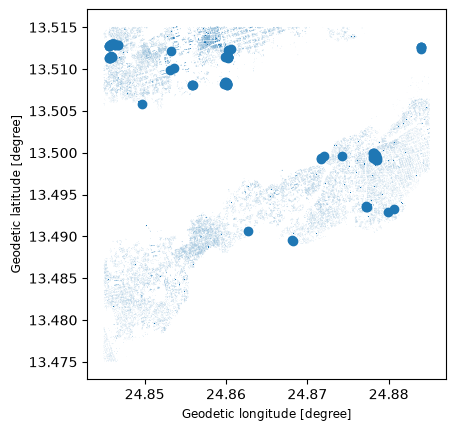

In [2]:
# Define a function that builds your AOI geometry from a shapefile you provide
def get_aoi_from_shapefile(shapefile_path):
    # Read the shapefile into a GeoDataFrame using geopandas
    aoi_gdf = gpd.read_file(shapefile_path)
    # Check that the shapefile actually has a coordinate reference system defined
    if aoi_gdf.crs is None:
        # Stop here if there's no CRS -- reprojecting without one would silently produce wrong coordinates
        raise ValueError("Shapefile has no CRS defined — cannot safely reproject. Check the .prj file.")
    # Reproject your shapefile to EPSG:4326 (standard lat/lon), so it matches the rest of this notebook
    aoi_gdf = aoi_gdf.to_crs("EPSG:4326")
    # Merge all features in the shapefile into a single geometry, in case it has multiple polygons
    geom = aoi_gdf.geometry.union_all()
    return geom
    
# ==================================================================================================
# DEFAULT AOI: the Sudan test area (latitude 13.495, longitude 24.865), so the notebook runs without prompts.
# TO DEFINE YOUR OWN AOI INTERACTIVELY AGAIN (type a point, or give a shapefile path):
#   uncomment the three lines marked [INTERACTIVE] below (mode, latitude, longitude)
#   and comment out the three lines marked [DEFAULT].
# For a shapefile, just set mode = "2" in the [DEFAULT] mode line; you will then be asked for the path.
# ==================================================================================================

# Choose how to define the AOI: by coordinates ("1") or by shapefile ("2")
# [INTERACTIVE] uncomment to be asked:
#mode= input ("Define AOI by (1) coordinates or (2) Shapefile? Enter 1 or 2: ").strip()
# [DEFAULT]
mode = "1"

# If you chose option 1, build a square AOI around a point you enter
if mode=="1": 
    # Ask you for the latitude of your point of interest
    # [INTERACTIVE] uncomment to type your own latitude:
    #lat= float(input("enter latitude:").strip())
    # [DEFAULT] Sudan test area
    lat = 13.495
    # Ask you for the longitude of your point of interest
    # [INTERACTIVE] uncomment to type your own longitude:
    #lon= float(input("enter longitude:").strip())
    # [DEFAULT] Sudan test area
    lon = 24.865
    # Set a buffer of 0.05 degrees (~5km) around your point
    buffer = 0.02  # ~5km
    # Build a square bounding box AOI centered on your coordinates
    geom = box(lon - buffer, lat - buffer, lon + buffer, lat + buffer)
    
# If you chose option 2, build the AOI from a shapefile you provide instead
elif mode=="2":
    # Ask you for the path to your .shp file, stripping any accidental quotes
    shapefile_path=input ("Enter path to the .shp file:").strip().strip('"\'')
    # Call the function above to turn your shapefile into an AOI geometry
    geom=get_aoi_from_shapefile(shapefile_path)

# If you entered anything other than 1 or 2, stop with an error rather than continuing silently
else:
    raise ValueError("Invalid choice-enter 1or 2.")

# The public Overpass servers are often overloaded, so several are tried in turn (see the query below)
OVERPASS_SERVERS = [
    "https://overpass.private.coffee/api",
    "https://overpass.kumi.systems/api",
    "https://overpass-api.de/api",
]
ox.settings.http_user_agent = "UniSalzburg-GBA-comparison/1.0 (emiliasophia.klaussner@plus.ac.at)"
ox.settings.requests_timeout = 100


# Query OSM's Overpass API (via osmnx) for all building features inside your AOI
# --- Fallback: read buildings from a Geofabrik OSM extract when every Overpass server is down ---
import os
import re

import geopandas as gpd
import pyogrio
import requests
from shapely.geometry import shape

GEOFABRIK_INDEX = "https://download.geofabrik.de/index-v1.json"
GEOFABRIK_HEADERS = {"User-Agent": "UniSalzburg-GBA-comparison/1.0 (emiliasophia.klaussner@plus.ac.at)"}


def pick_geofabrik_extract(geom):
    """Smallest Geofabrik extract whose outline contains the AOI (or, failing that, its centre)."""
    features = requests.get(GEOFABRIK_INDEX, headers=GEOFABRIK_HEADERS, timeout=120).json()["features"]
    extracts = [(f["properties"], shape(f["geometry"])) for f in features if f.get("geometry")]
    for target in (geom, geom.centroid):
        hits = [(props, outline) for props, outline in extracts if outline.contains(target)]
        if hits:
            props, _ = min(hits, key=lambda h: h[1].area)
            return props["id"], props["urls"]["pbf"]
    raise RuntimeError("No Geofabrik extract covers this AOI.")


def download_pbf(url, cache_dir="osm_cache"):
    """Download the extract once and reuse it on later runs."""
    os.makedirs(cache_dir, exist_ok=True)
    path = os.path.join(cache_dir, os.path.basename(url))
    if os.path.exists(path):
        print(f"Using cached extract {path}")
        return path
    print(f"Downloading {url} (one-time, can be several hundred MB) ...")
    tmp = path + ".part"
    with requests.get(url, headers=GEOFABRIK_HEADERS, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tmp, "wb") as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    os.replace(tmp, path)
    return path


def _tag(other_tags, key):
    """Pull one key out of GDAL's hstore-style other_tags string: "k"=>"v","k2"=>"v2"."""
    if not other_tags:
        return None
    m = re.search(r'"' + re.escape(key) + r'"=>"([^"]*)"', other_tags)
    return m.group(1) if m else None


def osm_buildings_from_geofabrik(geom, cache_dir="osm_cache"):
    """Offline-style fallback for ox.features_from_polygon(geom, tags={'building': True})."""
    name, url = pick_geofabrik_extract(geom)
    print(f"Geofabrik extract for this AOI: {name}")
    pbf = download_pbf(url, cache_dir)
    gdf = pyogrio.read_dataframe(
        pbf, layer="multipolygons", bbox=geom.bounds, where="building IS NOT NULL"
    )
    gdf = gdf[gdf.geometry.intersects(geom)].copy()
    # Same tag columns the notebook gets from osmnx
    for key in ("height", "building:levels"):
        gdf[key] = gdf["other_tags"].map(lambda s, k=key: _tag(s, k))
    return gdf.drop(columns=["other_tags"]).reset_index(drop=True)

# --- Query ---
buildings_osm = None  # filled by the retry loop below
# Try each server in turn, with a short pause between attempts. If every server fails, continue with an
# EMPTY OSM result instead of stopping, so the GBA and Google 2.5D sections can still run.
for attempt in range(2):
    for server in OVERPASS_SERVERS:
        ox.settings.overpass_url = server
        try:
            buildings_osm = ox.features_from_polygon(geom, tags={'building': True})
            print(f"OSM query succeeded via {server}")
            break
        except Exception as exc:
            print(f"OSM query failed via {server}: {type(exc).__name__}: {str(exc)[:120]}")
    if buildings_osm is not None:
        break
    time.sleep(10)

if buildings_osm is None:
    print("All Overpass servers failed - falling back to a Geofabrik extract (one-time download of a few hundred MB, cached in osm_cache/).")
    try:
        buildings_osm = osm_buildings_from_geofabrik(geom)
        print("OSM buildings read from Geofabrik extract (snapshot of the whole extract, not a live query).")
    except Exception as exc:
        print(f"Geofabrik fallback failed too: {type(exc).__name__}: {str(exc)[:150]}")
        print("WARNING: OSM is EMPTY, so OSM results below are NOT real. Re-run this cell later.")
        buildings_osm = gpd.GeoDataFrame({'geometry': []}, geometry='geometry', crs='EPSG:4326')

# Print how many OSM buildings were found in your AOI
print(len(buildings_osm))
# Draw a quick static plot of your OSM buildings, so you can sanity-check the result visually
if len(buildings_osm) > 0:
    buildings_osm.plot()


## 2. Add Global Buildings Atlas (GBA) Data

**Official source:** https://github.com/zhu-xlab/GlobalBuildingAtlas

**Mirror used by this notebook:** https://source.coop/tge-labs/globalbuildingatlas-lod1

### What this section does
This section gets you the actual GBA building footprint data for your AOI. It's split across three steps, spread over this cell and Sections 2.1 and 2.2 below:

1. **Work out which tile(s) you need** (this cell, via `get_tiles_from_geometry()`) - GBA is split into large 5x5 degree tiles, so first you calculate which tile filename(s) cover your AOI.
2. **Download those tile(s)** (Section 2.1) - fetch the actual `.parquet` file(s) from the mirror source to your computer.
3. **Load, combine, and filter them to your AOI** (Section 2.2) - turn the downloaded bytes into a usable geospatial table, and cut it down from a whole 5x5 degree tile to just the buildings inside your AOI.

**Why you want it:** GBA is one of the three datasets this notebook compares, and it's the only one of the three with near-complete building height data - you need this section's output to include GBA in that comparison at all.

**When can you skip it?** You can skip this entire section (this cell plus 2.1 and 2.2) if you only want to compare OSM against Google 2.5D. If you do skip it, also skip the GBA-specific parts of Sections 4 and 5 later on, since they reference a `buildings_gba` variable that only gets created here - running them without it will raise a `NameError`.

**Do you need to run it?** Yes, if GBA matters to your comparison - all three steps (this cell, 2.1, 2.2) need to run in order, since each one depends on the output of the one before it (tile filenames -> downloaded files -> filtered dataset).

**What does it load that you'll need later?** By the end of Section 2.2, you'll have a `buildings_gba` GeoDataFrame - the GBA equivalent of the `buildings_osm` variable from Section 1. This is what the comparison (Section 4) and mapping (Section 5) sections use downstream.

**What's the output?** A confirmation of which tile(s) were identified (this cell), followed by download progress and a preview table (2.1), and finally a count and plot of the GBA buildings inside your AOI specifically (2.2).

### Background: how GBA is distributed
GBA is far too large to distribute as a single file (2.75 billion buildings globally). Instead, it's split into **5 deg x 5 deg tiles** - rectangular chunks of the Earth's surface, each named after its corner coordinates (e.g. `e015_n65_e020_n60.parquet` covers 15-20E, 60-65N).

This means before downloading anything, you need to work out **which tile(s) your AOI actually falls inside** - your AOI might sit entirely within one tile, or straddle the edge between two (or more) tiles.

### What this cell does
`get_tiles_from_geometry()` looks at your AOI's bounding box and calculates which 5x5 degree tile(s) it overlaps, returning their exact filenames. This works for any geometry type (point, polygon, multipolygon).

### Expected output
A printed Python list of one or more `.parquet` tile filenames - these are the exact files that will be downloaded in the next step.

### How to interpret the result
- **One tile returned** -> your AOI is fully contained in a single tile. You can skip the optional "Tile Boundary Duplication Check" section later.
- **Two or more tiles returned** -> your AOI spans a tile boundary. This is worth noting, because buildings sitting exactly on that boundary line may need special handling - covered later in this notebook.


In [3]:
# Define a function that works out which GBA tile(s) your AOI falls inside
def get_tiles_from_geometry(geom):
    
    # Get your AOI's bounding box as (min longitude, min latitude, max longitude, max latitude)
    minx, miny, maxx, maxy = geom.bounds

    # Find all 5-degree tiles that overlap the bounding box
    # Round the minimum longitude down to the nearest 5-degree tile edge
    lon_start = math.floor(minx / 5) * 5
    # Round the minimum latitude down to the nearest 5-degree tile edge
    lat_start = math.floor(miny / 5) * 5

    # Start an empty list to collect the tile filenames you'll need
    tiles = []
    # Start scanning longitude from the rounded starting value
    lon = lon_start
    # Keep scanning eastward until you've passed your AOI's maximum longitude
    while lon < maxx:
        # For each longitude step, start scanning latitude from the rounded starting value
        lat = lat_start
        # Keep scanning northward until you've passed your AOI's maximum latitude
        while lat < maxy:
            # Set this tile's western edge
            lon_min = lon
            # Set this tile's eastern edge (5 degrees further east)
            lon_max = lon + 5
            # Set this tile's southern edge
            lat_min = lat
            # Set this tile's northern edge (5 degrees further north)
            lat_max = lat + 5

            # Work out whether the western edge is East or West of the prime meridian
            ew_min = 'e' if lon_min >= 0 else 'w'
            # Work out whether the eastern edge is East or West of the prime meridian
            ew_max = 'e' if lon_max >= 0 else 'w'
            # Work out whether the northern edge is North or South of the equator
            ns_max = 'n' if lat_max >= 0 else 's'
            # Work out whether the southern edge is North or South of the equator
            ns_min = 'n' if lat_min >= 0 else 's'

            # Build this tile's filename, following GBA's corner-coordinate naming convention
            tile = (
                f"{ew_min}{abs(lon_min):03d}_{ns_max}{abs(lat_max):02d}"
                f"_{ew_max}{abs(lon_max):03d}_{ns_min}{abs(lat_min):02d}.parquet"
            )
            # Add this tile's filename to your list
            tiles.append(tile)
            # Move one tile north and check again
            lat += 5
        # Move one tile east and check again
        lon += 5

    # Return the full list of tile filenames that overlap your AOI
    return tiles



# Run the function on your AOI geometry to get the list of tiles you need
tiles = get_tiles_from_geometry(geom)
# Print the tile filename(s) -- one tile means your AOI is fully inside it, more than one means it spans a boundary
print(tiles)


['e020_n15_e025_n10.parquet']


### 2.1 Download Tiles from the Mirror Source

Download the tile(s) identified above from the mirror source using the cell below. Ths source is developed to combine the dataset tiles that ar in two separate official Huggingface sites. Th code fetches the raw `.parquet` file(s) to your computer so you can load them in the next step. **This download is required if you want GBA in your comparison:** if you're prompted to confirm and answer `n`, the cell raises an error and stops, since every later GBA step depends on having the tile file(s) saved locally. 

### What this cell does
For each tile identified above, this function:

1. **Checks the file size first** without downloading the whole thing. It sends a lightweight "give me just the first byte" request and reads the server's reported total size from the response headers. GBA tiles can be tens to hundreds of MB, so this lets you see what you're committing to before downloading.
2. **Retries automatically** if the server doesn't respond, using exponential backoff (waiting 2s, then 4s, then 8s, etc. between attempts) - handles temporary network hiccups gracefully.
3. **Skips the download entirely** if the file already exists in your chosen save folder, making it safe to re-run this notebook without re-downloading the same tile twice.
4. **Asks for your confirmation** before actually downloading, once it knows the file size.

### What you'll be asked for
- **Save folder path** : where tiles should be stored on your computer (asked once, reused for all tiles)

### Expected output
- The reported size of each tile (in GB)
- A confirmation prompt per tile
- A preview (`.head(3)`) of the first downloaded tile's raw data table

### How to interpret the result
The preview table shows GBA's raw column structure before any filtering:

| Column | Meaning |
|---|---|
| `source` | Which input dataset this building's footprint came from (OSM, Microsoft, Google Open Buildings, or GBA's own satellite-derived pipeline) |
| `id` | Unique building identifier |
| `height` | Predicted building height in meters |
| `var` | Height prediction uncertainty/variance |
| `region` | Administrative region label |
| `bbox` | Bounding box of the building |
| `geometry` | The building's footprint, stored as binary (WKB) - this is what `geopandas` will convert into a usable shape in the next step |

> **Default output folder:** the cell is preset to the `imageoutput` folder next to this notebook and no longer asks for a path. To be asked again, uncomment the `[INTERACTIVE]` line and comment out the `[DEFAULT]` line (instructions at the top of the cell).


In [4]:

# Set a custom User-Agent header, since some servers reject requests with no/blank User-Agent
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; research-script/1.0)"}
# Build a reusable SSL context using certifi's trusted certificate bundle
SSL_CTX = ssl.create_default_context(cafile=certifi.where())


# Define a function that downloads a single GBA tile, with size-checking and retry logic
def download_gba_tile(tile_name, save_dir, max_retries=4, timeout=15, download_timeout=300):
    # Build the full download URL for this tile on the mirror source
    url = f"https://data.source.coop/tge-labs/globalbuildingatlas-lod1/{tile_name}"
    # Create your save folder if it doesn't already exist
    os.makedirs(save_dir, exist_ok=True)
    # Build the full local file path this tile will be saved to
    save_path = os.path.join(save_dir, tile_name)

    # If you've already downloaded this tile before, reuse it instead of downloading again
    if os.path.exists(save_path):
        print(f"{tile_name} already exists locally — skipping download.")
        return save_path

    # --- Step 1: check file size / server availability ---
    # Try up to max_retries times to check the tile's size before committing to a full download
    for attempt in range(1, max_retries + 1):
        try:
            # Request just the first byte (a "range" request), which returns the total size without downloading it all
            req = urllib.request.Request(url, headers={**HEADERS, "Range": "bytes=0-0"})
            with urllib.request.urlopen(req, context=SSL_CTX, timeout=timeout) as r:
                # Read the full file size out of the server's Content-Range response header
                size_bytes = int(r.headers.get("Content-Range", "0/0").split("/")[-1])
                # Print the tile's size in GB, so you know what you're about to download
                print(f"{tile_name} size: {size_bytes/1024**3:.2f} GB")
            # Size check succeeded -- stop retrying and continue
            break
        except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as e:
            # Print what went wrong on this attempt
            print(f"Attempt {attempt} failed: {e}")
            if attempt < max_retries:
                # Wait longer after each failed attempt (2s, 4s, 8s, ...) before retrying
                wait = 2 ** attempt
                print(f"Retrying in {wait}s...")
                time.sleep(wait)
            else:
                # Give up after the last allowed attempt
                print("Giving up after max retries.")
                return None
    else:
        # This runs only if the for-loop finished without ever hitting "break" (i.e. every attempt failed)
        return None

    # Tell you where the file will be saved, then start downloading automatically -- no confirmation needed
    print(f"Will save to: {save_path}")

    # --- Step 2: actual download, chunked, with its own retry loop ---
    # Try up to max_retries times to complete the full download
    for attempt in range(1, max_retries + 1):
        try:
            # Build the actual (non-range) download request
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, context=SSL_CTX, timeout=download_timeout) as response:
                # Read the total expected file size from the response headers, if provided
                total = int(response.headers.get("Content-Length", 0))
                # Track how many bytes you've downloaded so far
                downloaded = 0
                # Open the local file for writing in binary mode
                with open(save_path, "wb") as out_file:
                    while True:
                        # Read the next 1MB chunk from the response
                        chunk = response.read(1024 * 1024)  # 1MB at a time
                        if not chunk:
                            # No more data -- the download is complete
                            break
                        # Write this chunk to your local file
                        out_file.write(chunk)
                        # Update your running total of bytes downloaded
                        downloaded += len(chunk)
                        if total:
                            # Print a live progress update (overwriting the same line) if the total size is known
                            print(f"\r{tile_name}: {downloaded/1024**2:.1f} / {total/1024**2:.1f} MB",
                                  end="", flush=True)
            # Print a newline so the next message doesn't run into the progress line
            print()
            # Confirm the file was saved successfully
            print(f"Saved: {save_path}")
            # Return the local file path so the calling code knows where to find it
            return save_path
        except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as e:
            # Print what went wrong on this download attempt
            print(f"\nDownload attempt {attempt} failed: {e}")
            if os.path.exists(save_path):
                # Remove any partial/corrupt file before retrying, so you don't keep a broken download
                os.remove(save_path)
            if attempt < max_retries:
                # Wait longer after each failed attempt before retrying
                wait = 2 ** attempt
                print(f"Retrying download in {wait}s...")
                time.sleep(wait)
            else:
                # Give up after the last allowed attempt
                print("Giving up on download after max retries.")
                return None


# --- ask ONCE for the save folder, reused for all tiles ---
# Ask you where you want the downloaded tile(s) saved on your computer
# ==================================================================================================
# DEFAULT OUTPUT FOLDER: "imageoutput" next to this notebook. It holds the downloaded GBA tile(s) and the
# GeoJSON files saved later (GBA and Google 2.5D). Tiles already in this folder are not downloaded again.
# TO BE ASKED FOR A FOLDER AGAIN: uncomment the [INTERACTIVE] line and comment out the [DEFAULT] line.
# ==================================================================================================
# [INTERACTIVE] uncomment to be asked:
#save_dir = input("Where should the tiles be saved? (enter folder path): ").strip().strip('"\'')
# [DEFAULT]
save_dir = os.path.join(os.getcwd(), "imageoutput")

# Start an empty list to collect the local paths of each successfully downloaded tile
tile_paths = []
# Loop over every tile filename identified earlier
for t in tiles:
    # Download this tile (or reuse it if already downloaded)
    tile_path = download_gba_tile(t, save_dir)
    if tile_path is None:
        # Stop the notebook here if a download failed after all retries -- later steps can't proceed without it
        raise RuntimeError(f"Download failed for {t}.")
    # Add this tile's local path to your list
    tile_paths.append(tile_path)

# Print a summary of everything you downloaded
print(f"\nDownloaded {len(tile_paths)} tile(s): {tile_paths}")

e020_n15_e025_n10.parquet already exists locally — skipping download.

Downloaded 1 tile(s): ['c:\\Users\\b1104579\\OneDrive - Universität Salzburg\\Dokumente\\PopEval\\ChippoInternship\\ChippoInternshipGlobalBuildingAtlas\\imageoutput\\e020_n15_e025_n10.parquet']


### 2.2 Convert Tile Data into Usable Geometry, and Filter to Your AOI

### Background: why this step is necessary
Downloading a tile only gets you **bytes on disk** - it doesn't give you a working dataset yet. This step:

1. **Loads each tile** Opens each tile so the building shapes inside it become real, usable shapes on a map (not just raw, unreadable data).
2. **Combines multiple tiles** Merges tiles together, if your AOI needed more than one tile
3. **Filters down to just your AOI** using `.intersects(geom)` Keeps only the buildings inside your AOI. A tile covers a huge area (possibly over a million buildings), so this step throws away everything except the small part you actually care about
4. **Optionally exports the result as GeoJSON** - useful if you want to open this AOI-specific subset in QGIS, ArcGIS, or share it with a colleague without needing to re-run this notebook.

### What you'll be asked for
- **Save as GeoJSON? (y/n)** : optional export step

### Expected output
- Confirmation of how many tiles were combined and the total row count
- The dataset's actual **CRS** (Coordinate Reference System) :  important to check rather than assume, since GBA tiles are not always labeled EPSG:4326 correctly
- A printed count of buildings found within your AOI specifically
- A quick plot of just those AOI buildings

### How to interpret the result
The `Buildings intersecting AOI` count is your **actual GBA building count for this AOI** : this is the number you'll use in the comparison section later, not the full tile's row count.


Combined 1 tile(s) — total rows: 4134960
OGC:CRS84
   source             id    height       var region  \
0  google  7G46FXWC+FG54  1.660938  0.636230    SDN   
1  google  7G46FXVF+MF6C  0.682637  0.172652    SDN   
2  google  7G46FXWF+49P8  0.652470  0.062614    SDN   
3  google  7G46FXWF+4922  0.934944  0.135695    SDN   
4  google  7G46FXWF+3C8X  1.147444  0.234350    SDN   

                                                bbox  \
0  {'xmin': 24.9713278387173, 'ymin': 12.49609599...   
1  {'xmin': 24.9736033950638, 'ymin': 12.49414279...   
2  {'xmin': 24.9734196457198, 'ymin': 12.49530465...   
3  {'xmin': 24.973354292703203, 'ymin': 12.495229...   
4  {'xmin': 24.9735642634709, 'ymin': 12.49514536...   

                                            geometry  
0  POLYGON ((24.97139 12.49611, 24.97138 12.49616...  
1  POLYGON ((24.97365 12.49418, 24.9736 12.49418,...  
2  POLYGON ((24.97349 12.49534, 24.97344 12.49536...  
3  POLYGON ((24.9734 12.49524, 24.97338 12.49528,...  
4  POL

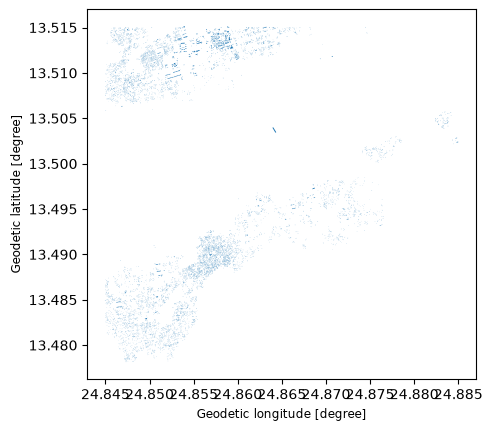

In [5]:

# Load each downloaded tile into a GeoDataFrame, automatically decoding the WKB geometry column into real shapes
gdfs = [gpd.read_parquet(p) for p in tile_paths]
# Combine all loaded tiles into a single GeoDataFrame (a no-op if you only had one tile)
gdf = gpd.GeoDataFrame(pd.concat(gdfs, ignore_index=True), crs=gdfs[0].crs)
# Print how many tiles you combined and the total number of building rows across them
print(f"Combined {len(gdfs)} tile(s) — total rows: {len(gdf)}")
# Confirm what CRS it actually is, rather than assuming EPSG:4326
print(gdf.crs)
# Print the first few rows so you can inspect the raw column structure
print(gdf.head())

# Filter the combined dataset down to only the buildings that actually fall inside your AOI
buildings_gba = gdf[gdf.geometry.intersects(geom)]
# Print how many GBA buildings were found within your AOI specifically
print(f"Buildings intersecting AOI: {len(buildings_gba)}")
# Draw a quick static plot of your AOI's GBA buildings, so you can sanity-check the result visually
buildings_gba.plot()

# Ask you whether you want to save this AOI-filtered subset as a GeoJSON file
save_geojson = input("Save the AOI buildings as Geojson? (y/n):").strip().lower()
# If you answered "y", export the buildings to a GeoJSON file in your save folder
if save_geojson == "y":
    # Build the output file path inside your save folder
    aoi_geojson_path = os.path.join(save_dir, "buildings_gba_aoi.geojson")
    # Write the AOI-filtered GBA buildings out as GeoJSON
    buildings_gba.to_file(aoi_geojson_path, driver="GeoJSON")
    # Confirm where the file was saved
    print(f"Saved AOI-filtered buildings as: {aoi_geojson_path}")



## Tile Boundary Duplication Check (Optional)

**Only run this section if Section 2 returned more than one tile** ( i.e. your AOI spans a tile boundary). If only one tile was returned, skip ahead to Section 3.

### Background: why this matters
GBA's documentation does not specify how buildings that sit exactly on a tile boundary are handled. Since building fusion happens *before* the final 5x5 degree export, a building straddling that line could end up:

- **Double-counted** : split into two separate buildings with different IDs, one per tile
- **Safely duplicated** : the same building, same ID, identical geometry, appearing in both tiles (easy to fix - just drop duplicate IDs)
- **Clipped/split** : same ID, but a different, partial geometry in each tile (would need to be spatially merged back together before measuring area or volume)

Since this isn't documented anywhere, this section tests it **empirically**, using your own downloaded tiles.

### What these cells do
1. **Visual check** : plots buildings near the tile boundary line, so you can visually spot any oddly-split or duplicated shapes.
2. **Programmatic check** : looks for building `id`s that appear in more than one tile, and compares their geometry to determine which of the three cases above applies.
3. **Zoomed visual check** : a closer, cropped view specifically around the boundary line (much faster to render than plotting the entire combined dataset).

### Expected output
A count of duplicate IDs found, and :  if any exist - a direct geometry comparison telling you whether they're identical (safe to deduplicate) or different (needs merging).

### How to interpret each possible result

| Result | What it means | What to do |
|---|---|---|
| No duplicate IDs found | Each tile likely assigned separate IDs to a boundary-crossing building - risk of **double-counting** in totals | Manually inspect buildings near the boundary line to confirm |
| Duplicate IDs, **identical** geometry | Safe duplication - same building appears whole in both tiles | Drop duplicates: `gdf.drop_duplicates(subset="id")` |
| Duplicate IDs, **different** geometry | The building was clipped/split at the tile edge | Spatially dissolve/union the fragments before measuring area or volume |
| No buildings found near the boundary at all | Inconclusive - this AOI simply didn't have a building sitting exactly on the line | Not evidence either way; try a different boundary-straddling AOI if you need a definitive answer |

NameError: name 'bounds_list' is not defined

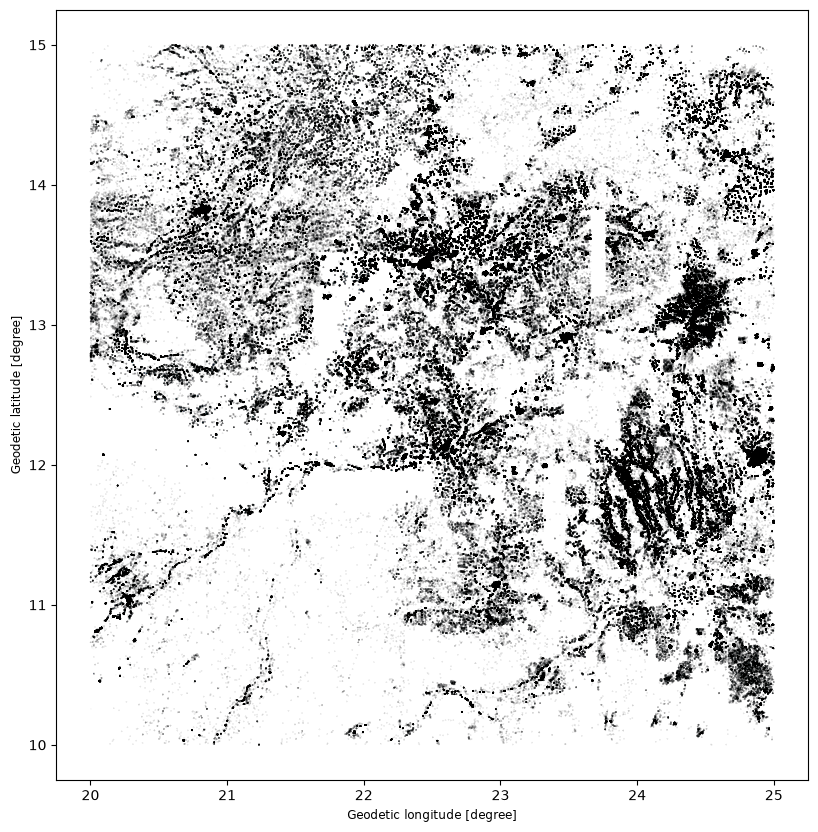

In [6]:
# Import matplotlib's plotting interface, used for this visual boundary check
import matplotlib.pyplot as plt

# Create a new figure and axis, sized 10x10 inches, to plot your combined buildings on
fig, ax = plt.subplots(figsize=(10, 10))
# Plot all combined buildings (from both/all tiles) with black outlines and half transparency
gdf.plot(ax=ax, edgecolor="black", alpha=0.5)
# Draw the tile boundary line for reference
# Take the east edge of the first tile as the boundary — adjust this if your tiles share a different edge
boundary_lon = bounds_list[0][2]
# Draw a dashed red vertical line at the tile boundary, so you can see which buildings sit near it
ax.axvline(boundary_lon, color="red", linestyle="--", label="Tile boundary")
# Show the legend so the boundary line is labeled
ax.legend()
# Give the plot a descriptive title
plt.title("Buildings near tile boundary — check for split/duplicate polygons visually")
# Display the plot
plt.show()


In [ ]:
# --- Investigate whether buildings crossing the tile edge are split or duplicated ---

# 1. Only meaningful if you have more than one tile
if len(gdfs) < 2:
    # Nothing to check if your AOI only needed a single tile
    print("Only one tile was loaded — no tile boundary exists to test.")
else:
    # get the boundary line between the two tiles (works for a simple 2-tile case)
    # this assumes the tiles are adjacent either east-west or north-south
    # Recompute each tile's bounding box: [minx, miny, maxx, maxy]
    bounds_list = [g.total_bounds for g in gdfs]
    # Print a header before listing each tile's bounds
    print("Tile bounds:")
    # Print the bounds of every tile you loaded, so you can see where they sit
    for i, b in enumerate(bounds_list):
        print(f"  Tile {i}: {b}")

    # find duplicate IDs across the combined dataset — same ID appearing in >1 tile
    # Flag every row whose "id" value appears more than once across the combined dataset
    dupe_mask = gdf["id"].duplicated(keep=False)
    # Pull out just those duplicated rows, sorted by id so matching pairs sit next to each other
    dupes = gdf[dupe_mask].sort_values("id")

    # Print how many distinct building IDs were duplicated across tiles
    print(f"\nBuildings with duplicate IDs across tiles: {dupes['id'].nunique()}")

    if len(dupes) > 0:
        # Show a preview of the duplicated buildings, if any were found
        print("\nSample of duplicated buildings:")
        print(dupes[["id", "source", "height"]].head(10))

        # check whether the geometry is identical or different (clipped) for a duplicate ID
        # Pick the first duplicated ID as a sample case to inspect closely
        sample_id = dupes["id"].iloc[0]
        # Pull out every row (i.e. every tile's copy) of that sample building
        matches = gdf[gdf["id"] == sample_id]
        # Report how many rows (tiles) that sample ID was found in
        print(f"\nInspecting id={sample_id} — found in {len(matches)} rows")
        # Print the area and bounds of each copy, so you can compare them visually
        for idx, row in matches.iterrows():
            print(f"  Area: {row.geometry.area:.8f} | Bounds: {row.geometry.bounds}")

        # Take the geometry from the first copy of the sample building
        geom_a = matches.geometry.iloc[0]
        # Take the geometry from the second copy of the sample building
        geom_b = matches.geometry.iloc[1]
        # Check whether the two copies are geometrically identical (safe duplicate) or not (clipped/split)
        print(f"\nGeometry identical across tiles? {geom_a.equals(geom_b)}")
    else:
        # No duplicate IDs found -- explain what that could mean
        print("No duplicate IDs found — either buildings near the boundary got unique IDs per tile (split/counted separately), or no building happens to straddle the exact line in this AOI.")


Only one tile was loaded — no tile boundary exists to test.


Tile bounds: [array([19.9999508 , 10.00009499, 25.00015255, 15.00020666])]
Buildings near boundary: 80067


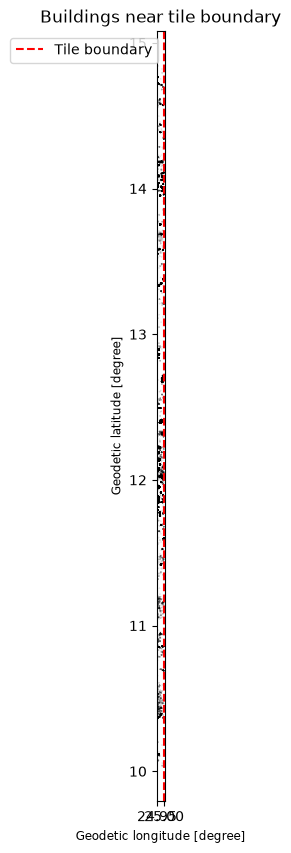

In [28]:
# recreate bounds_list from your loaded tile GeoDataFrames
# Recompute each tile's bounding box, in case you're running this cell on its own
bounds_list = [g.total_bounds for g in gdfs]
# Print the bounds so you can see them
print("Tile bounds:", bounds_list)

# Use the east edge of the first tile as the boundary line to zoom in on
boundary_lon = bounds_list[0][2]  # east edge of the first tile
# Set how far (in degrees) on either side of the boundary you want to zoom in
zoom_buffer = 0.05

# Select only the buildings that fall within zoom_buffer degrees of the boundary line
near_boundary = gdf.cx[boundary_lon - zoom_buffer : boundary_lon + zoom_buffer, :]
# Print how many buildings fall in that narrow zone
print(f"Buildings near boundary: {len(near_boundary)}")

# Create a new figure and axis for the zoomed-in plot
fig, ax = plt.subplots(figsize=(10, 10))
# Plot just the buildings near the boundary (much faster than plotting everything)
near_boundary.plot(ax=ax, edgecolor="black", alpha=0.5)
# Draw a dashed red vertical line marking the exact tile boundary
ax.axvline(boundary_lon, color="red", linestyle="--", label="Tile boundary")
# Show the legend so the boundary line is labeled
ax.legend()
# Give the plot a descriptive title
plt.title("Buildings near tile boundary")
# Display the plot
plt.show()



## 3. Add Google Open Buildings 2.5D Temporal Data

### Background: why this section works differently from Sections 1 and 2
OSM and GBA are **vector** datasets - discrete building polygons you can count, measure, and filter individually. Google Open Buildings 2.5D Temporal is a **raster** dataset - a grid of 4 m pixels, each holding values for building presence (0-1 confidence), fractional building count, and height. There are no discrete "buildings" in the source data.

This section therefore gives you Google 2.5D in **two forms**:

1. **Raster statistics (3.2)** - aggregate statistics (mean/sum) over the pixels inside your AOI, for example a built-up area. This is the most direct, least processed use of the data.
2. **Derived vectors (3.3)** - approximate building polygons made from the raster (threshold the presence band, split touching blobs, polygonize), stored in `buildings_g25d`. This lets Google 2.5D sit next to OSM and GBA in the comparison and on the map. **These are modeled shapes, not traced footprints:** the polygon count and sizes depend on the threshold and splitting settings, so treat them as approximate.

Section 3.4 shows how strongly the results depend on the presence threshold. In dense settlements of small structures the dependence can be very large, so read that table before interpreting any Google 2.5D number.

### Coverage reminder
Google 2.5D covers **Africa, South Asia, Southeast Asia, and Latin America & the Caribbean only** - it does **not** cover Europe or North America. If your AOI falls outside this coverage, the queries below find zero matching images, not a descriptive error. This is itself a valid, reportable finding - simply note that Google 2.5D could not be evaluated for that AOI.

### 3.0 One-time setup: Google Earth Engine authentication

**What this cell does:** authenticates your Google account (the `ee.Authenticate()` line is commented out; uncomment it for the very first run, which opens a browser login) and initializes a connection using your Google Cloud project.

**What you'll be asked for:** a browser login/authorization the first time you run this on a given computer; a valid Google Cloud project ID with the Earth Engine API enabled (see Prerequisites in the introduction above).

**Expected output:** `1` on success. If you see an error, it is almost always one of: (1) authentication not completed, (2) the project ID doesn't exist or isn't yours, or (3) the Earth Engine API not yet enabled for that project - each produces a distinct, descriptive error message pointing you to the fix.

In [27]:

# Trigger the (one-time, per environment) browser login flow to authenticate your Google account
#ee.Authenticate()
# Initialize your Earth Engine session using your own Google Cloud project ID
ee.Initialize(project="buildingheight-513011")  # replace with your actual Google Cloud project ID

# sanity check -- should print 1 if authentication and initialization both worked
print(ee.Number(1).getInfo())


1


### 3.1 Convert Your AOI into an Earth Engine Geometry

### Background
To access the dataseset, GEE needs a redefined AOI. The `geom` variable from Section 1 (built from either coordinates or your shapefile) is reused directly here. Earth Engine will convert from a Shapely object into its own geometry,  `ee.Geometry` format.

### Expected output
No visible output. Rather this cell just creates the `ee_geom` variable used by the rest of Section.

In [26]:

#For shapefileds that have Z-coordinates, you can use the following function to drop the Z-coordinate and force the geometry to 2D:
def drop_z(geometry):
    """Remove the Z-coordinate from any geometry, forcing it to 2D."""
    return transform(lambda x, y, z=None: (x, y), geometry)
geom_2d = drop_z(geom)
print(geom_2d.has_z)  # should now print False to confirm that now the geometry is 2D

#mapping converts the shapely geometry to GeoJSON format, which is compatible with Google Earth Engine
ee_geom = ee.Geometry(mapping(geom_2d))
print("Success")


False
Success


### 3.2 Query Building Presence and Height Statistics

### What this cell does
The function `get_2_5d_stats()`:

1. Loads the Google 2.5D image collection, filtered to a *chosen year and months* and your AOI. 2019 was choosen as the year since GBA is as of 2019.
2. Mosaics the result (in case your AOI spans more than one source image tile).
3. Computes **raw, AOI-wide statistics** - mean and sum of `building_presence` and `building_height` across *every* pixel in your AOI, including empty (non-building) space.
4. Computes a **second, masked height statistic** - restricting the height calculation to only pixels where `building_presence` exceeds a 0.5 confidence threshold (The model's probability for building or not ranges 0-1, 0 being definate no, 1 being a definate yes. 0.5 would be the midpoint), giving a meaningful "average height of actual buildings" figure rather than one diluted by empty ground.

### Things to note
- The **raw `building_height_mean`** (from step 3) will look artificially small - it is averaged across the whole AOI, including non-building pixels that are masked to zero. Do not report this number as a representative building height; use the **masked** version from step 4 instead.
- `building_presence` is a **fractional confidence value per pixel (0-1)**, not a binary building/no-building flag - this is why we sum it (as a proxy for total building coverage) rather than simply counting pixels.

### Expected output
Two dictionaries printed: raw AOI-wide stats, and building-only (masked) height stats.

### How to interpret the result - worked example (Tawila AOI)
In this project's own Tawila test, the raw output was:
```
{'building_height_mean': 0.028, 'building_height_sum': 220095.8,
 'building_presence_mean': 0.0053, 'building_presence_sum': 41121.6}
```
The `building_height_mean` of 0.028m is the artificially-diluted whole-AOI figure described above - not usable on its own. The `building_presence_sum` (41,121.6), however, is directly usable: multiplied by pixel area, it converts into a built-up area estimate (see the next cell).

In [25]:
# Define a function that queries Google 2.5D's building presence/height statistics for your AOI. Change the year parameter to get data for different years (2019-2023).
def get_2_5d_stats(ee_geom, year=2019):
    # Load the image collection and create a mosaic (in case AOI spans multiple source tiles)
    # Load the Google 2.5D image collection
    collection = ee.ImageCollection("GOOGLE/Research/open-buildings-temporal/v1") \
        .filterDate(f"{year}-01-01", f"{year}-12-31") \
        .filterBounds(ee_geom)
    # Merge all matching images into a single mosaic covering your AOI
    image = collection.mosaic()

    # Raw stats -- mean/sum across the WHOLE AOI, including non-building pixels
    # Compute mean and sum of building_presence and building_height across every pixel in your AOI
    stats = image.select(["building_presence", "building_height"]).reduceRegion(
        reducer=ee.Reducer.mean().combine(ee.Reducer.sum(), sharedInputs=True),
        geometry=ee_geom,
        scale=4,
        maxPixels=1e9
    ).getInfo()

    # Masked stats -- height averaged ONLY over pixels confidently classified as building
    # Build a mask of pixels where building_presence exceeds a 0.5 confidence threshold
    built_mask = image.select("building_presence").gt(0.5)
    # Apply that mask to the height band, so only building pixels are kept
    height_masked = image.select("building_height").updateMask(built_mask)

    # Compute mean height and pixel count, restricted to just those masked building pixels
    height_stats = height_masked.reduceRegion(
        reducer=ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True),
        geometry=ee_geom,
        scale=4,
        maxPixels=1e9
    ).getInfo()

    # Return both the raw AOI-wide stats and the building-only masked height stats
    return stats, height_stats


# Run the function for year 2019 on your AOI
stats_2_5d, height_stats_2_5d = get_2_5d_stats(ee_geom, year=2019)
# Print the raw, whole-AOI statistics
print("Raw AOI-wide stats:", stats_2_5d)
# Print the building-only (masked) height statistics
print("Building-only height stats:", height_stats_2_5d)

"Check first: if collection has zero images, your AOI likely falls outside Google 2.5D's coverage"
"(Google 2.5D covers Africa, South/Southeast Asia, Latin America & the Caribbean only -- no Europe/North America)"


Raw AOI-wide stats: {'building_height_mean': 0.08622742893438956, 'building_height_sum': 106858.02233455885, 'building_presence_mean': 0.014243408146457578, 'building_presence_sum': 17651.25604049389}
Building-only height stats: {'building_height_count': 2093, 'building_height_mean': 4.224170936946148}


'(Google 2.5D covers Africa, South/Southeast Asia, Latin America & the Caribbean only -- no Europe/North America)'

### Converting presence into a comparable built-up area figure

### Background
`building_presence_sum` is the sum of the per-pixel confidence values, so it is a "soft" coverage estimate: a pixel with confidence 0.2 contributes 0.2 pixels of building. Multiplying by the pixel area (4m x 4m = 16m2) converts it into an area, directly comparable to the OSM/GBA footprint totals computed in Section 4.

**Note:** this soft sum is a different method from the threshold-based areas in Sections 3.3 and 3.4, where a pixel either counts fully (confidence above the threshold) or not at all. In areas with many small structures the two can differ by an order of magnitude, because small buildings often receive low confidence values. Section 3.4 puts both side by side.

### Expected output
A built-up area figure in km squared.

### Hypothesis on result
The results may be affected by GBA's tendency to merge adjacent buildings into single polygons, and differences in native imagery resolution (GBA: 3m PlanetScope; Google 2.5D: 10m Sentinel-2, modeled to an effective 4m).

In [24]:
# Set the pixel area: each Google 2.5D pixel represents 4m x 4m = 16 square meters on the ground
pixel_area_m2 = 4 * 4  # 4m effective resolution

# Convert the summed building-presence value into a built-up area in square kilometers
built_up_area_km2 = (stats_2_5d["building_presence_sum"] * pixel_area_m2) / 1e6
# Print the resulting built-up area figure
print(f"Google 2.5D built-up area (soft sum of presence): {built_up_area_km2:.4f} km2")


Google 2.5D built-up area (soft sum of presence): 0.2824 km2


### 3.3 Vectorise Google 2.5D (derived building polygons)

### What this cell does
It downloads the three 2.5D bands for your AOI once (as 4 m pixels in a local UTM projection) and turns them into approximate building polygons, using the helper script `google25d_to_vector.py` that sits next to this notebook:

1. **Threshold:** pixels with `building_presence` above `G25D_THRESHOLD` count as building.
2. **Split touching buildings:** blobs of building pixels are split with a distance-transform watershed, so that adjacent buildings do not become one big polygon. This is a geometric guess based on shape, not on any building ID.
3. **Polygonize and clean:** each blob becomes a polygon; polygons are lightly simplified (1.5 m) and anything under 20 m2 is dropped.
4. **Attach statistics:** each polygon gets its mean/median/max `building_height`, mean presence and area.

The result is the GeoDataFrame `buildings_g25d` (EPSG:4326), used by Sections 3.4, 4 and 5.

### Settings you may want to change
- `G25D_THRESHOLD` (default 0.5): see Section 3.4 for how much this matters.
- `G25D_YEAR` (default 2019, to match GBA).

### Requirements
Run this notebook from the folder that contains `google25d_to_vector.py`, and run Section 3.0 first (Earth Engine must be initialized). If your AOI is outside Google 2.5D's coverage, the cell says so and sets `buildings_g25d = None`; Sections 4 and 5 then leave Google 2.5D out.

### How to interpret the result
- These polygons are **modeled**, not surveyed. Use them for approximate side-by-side comparison, not for exact building counts.
- Polygon count, size and area move a lot with the threshold. Do not report a count without stating the threshold.

AOI area: 19.17 km2, working CRS EPSG:32635
Found 1 source image(s) for 2019.
Downloaded tile 1/4
Downloaded tile 2/4
Downloaded tile 3/4
Downloaded tile 4/4

Google 2.5D polygons (threshold 0.5): 301
Total area:          0.0257 km2
Median polygon area: 64 m2
Median height:       4.0 m


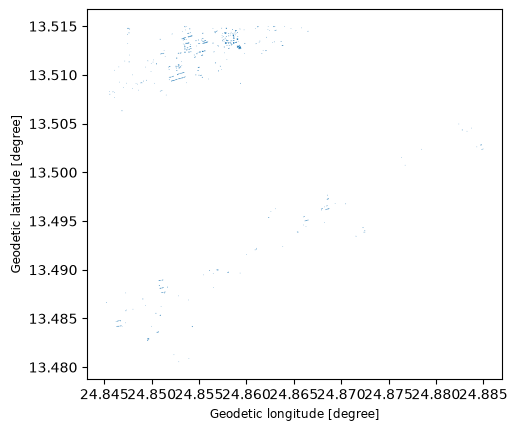

In [23]:
# Make the helper script importable (the notebook must be run from the folder that contains it)
import sys
import importlib
sys.path.insert(0, os.getcwd())
import google25d_to_vector as g25
importlib.reload(g25)  # pick up edits to the script without restarting the kernel

# Settings
G25D_YEAR = 2019        # 2019 to match GBA; 2.5D covers 2016-2023
G25D_THRESHOLD = 0.5    # building_presence cutoff for "building pixel" -- see Section 3.4 for its effect

try:
    # Download the three bands once. Section 3.4 reuses this download, so nothing is fetched twice.
    g25d_raster = g25.fetch_raster(geom_2d, year=G25D_YEAR)
    # Threshold, split touching blobs, polygonize
    buildings_g25d = g25.vectorize_raster(g25d_raster, threshold=G25D_THRESHOLD)
except RuntimeError as exc:
    # Raised when no 2.5D images exist for this AOI/year, i.e. most likely outside the coverage area
    print(f"Google 2.5D vectors not available: {exc}")
    g25d_raster = None
    buildings_g25d = None

if buildings_g25d is not None:
    print(f"\nGoogle 2.5D polygons (threshold {G25D_THRESHOLD}): {len(buildings_g25d)}")
    if len(buildings_g25d) > 0:
        print(f"Total area:          {buildings_g25d['area_m2'].sum() / 1e6:.4f} km2")
        print(f"Median polygon area: {buildings_g25d['area_m2'].median():.0f} m2")
        print(f"Median height:       {buildings_g25d['height_mean'].median():.1f} m")
        buildings_g25d.plot()
    else:
        print("No pixels passed the threshold. Try a lower G25D_THRESHOLD (see Section 3.4).")

In [22]:
# Save the derived Google 2.5D polygons as GeoJSON.
# The file name contains the year and threshold, so results from different thresholds do not overwrite each other.
if "buildings_g25d" not in globals() or buildings_g25d is None:
    print("Nothing to save: Section 3.3 has not been run, or found no Google 2.5D coverage for this AOI.")
elif len(buildings_g25d) == 0:
    print("Nothing to save: no pixels passed the threshold (try a lower G25D_THRESHOLD).")
else:
    # Same folder as the GBA tiles if you gave one in Section 2.1, otherwise the notebook's folder
    out_dir = save_dir if "save_dir" in globals() and save_dir else os.getcwd()
    os.makedirs(out_dir, exist_ok=True)
    g25d_path = os.path.join(out_dir, f"google25d_{G25D_YEAR}_thr{G25D_THRESHOLD}.geojson")
    buildings_g25d.to_file(g25d_path, driver="GeoJSON")
    print(f"Saved {len(buildings_g25d)} Google 2.5D polygons (EPSG:4326) to: {g25d_path}")


Saved 301 Google 2.5D polygons (EPSG:4326) to: c:\Users\b1104579\OneDrive - Universität Salzburg\Dokumente\PopEval\ChippoInternship\ChippoInternshipGlobalBuildingAtlas\imageoutput\google25d_2019_thr0.5.geojson


### 3.4 Threshold Sensitivity Check (Recommended)

### Background
The confidence threshold that decides what counts as a "building pixel" (3.2 and 3.3) is an analyst choice, and it is the largest source of uncertainty in any Google 2.5D comparison. This cell repeats the vectorisation at four thresholds (0.2, 0.3, 0.5, 0.7) using the raster already downloaded in 3.3, and shows for each:

- the built-up area from simply counting pixels above the threshold,
- the number of derived polygons,
- the median polygon area.

It also shows the soft-sum area from 3.2 (no threshold), and the OSM and GBA footprint areas for reference.

### Expected output
A table with one row per threshold, then the reference areas.

### How to interpret the result
- If the area changes by a large factor between thresholds, that is a **reliability caveat to state explicitly** in any report: Google 2.5D's area and polygon count are far more sensitive to a methodological choice than OSM's or GBA's polygon-based counts, which have no such parameter.
- In areas with many small structures (for example dense informal settlements or camps) small buildings often get low confidence values, so a strict threshold can miss most of them while a low threshold recovers much more area. A low threshold also merges more buildings, so more polygons is not automatically better.
- Do not silently pick the threshold that looks best. Report the spread, and say which threshold your headline number uses.

In [21]:
import numpy as np
from rasterio.features import rasterize

if g25d_raster is None:
    print("Google 2.5D raster not available (Section 3.3 found no coverage) -- skipping the threshold check.")
else:
    pixel_m2 = g25.PIXEL_M ** 2
    presence = g25d_raster["arr"][0]
    # Pixels inside the AOI only (the downloaded tiles can extend past it)
    aoi_mask = rasterize([(g25d_raster["aoi_utm"], 1)], out_shape=presence.shape,
                         transform=g25d_raster["transform"], fill=0).astype(bool)

    rows = []
    for thr in [0.2, 0.3, 0.5, 0.7]:
        polys = g25.vectorize_raster(g25d_raster, threshold=thr)
        rows.append({
            "threshold": thr,
            "pixel_area_km2": ((presence > thr) & aoi_mask).sum() * pixel_m2 / 1e6,
            "polygons": len(polys),
            "median_polygon_m2": polys["area_m2"].median() if len(polys) else np.nan,
        })
    sensitivity = pd.DataFrame(rows).round(4)
    print(sensitivity.to_string(index=False))

    # Reference points: soft sum (3.2 method, no threshold) and the vector datasets, in the same local UTM CRS
    soft_km2 = (presence * aoi_mask).sum() * pixel_m2 / 1e6
    print(f"\nSoft sum of presence (no threshold):  {soft_km2:.4f} km2")
    utm = g25d_raster["crs"]
    for name in ("buildings_osm", "buildings_gba"):
        data = globals().get(name)
        if data is not None and len(data) > 0:
            print(f"{name} footprint area: {data.to_crs(utm).geometry.area.sum() / 1e6:.4f} km2")
    spread = sensitivity["pixel_area_km2"].max() / max(sensitivity["pixel_area_km2"].min(), 1e-9)
    print(f"\nArea spread between the strictest and loosest threshold: x{spread:.1f}")

 threshold  pixel_area_km2  polygons  median_polygon_m2
       0.2          0.3542      3411               64.0
       0.3          0.1126      1423               32.0
       0.5          0.0321       301               64.0
       0.7          0.0142       165               48.0

Soft sum of presence (no threshold):  0.2729 km2
buildings_osm footprint area: 0.4343 km2
buildings_gba footprint area: 0.1784 km2

Area spread between the strictest and loosest threshold: x24.9


### Notes on Google 2.5D - summary before moving to comparison

- **Structural difference**: the source is a raster, not vector. The polygons in `buildings_g25d` are derived from it (threshold, blob splitting, polygonizing) and are approximate. Raster statistics (3.2) remain the most direct use of the data.
- **Threshold dependence**: area and polygon count depend strongly on the presence threshold (see 3.4). Always state the threshold next to any Google 2.5D number.
- **Counts**: polygon counts also depend on the blob-splitting settings, and can be far from OSM's counts, especially for many small structures. Do not treat them as exact building counts.
- **Coverage**: Africa, South Asia, Southeast Asia, Latin America & the Caribbean only. Always confirm that images were found before trusting a zero/empty result - it may mean your AOI is outside coverage, not that no buildings exist.
- **Height accuracy**: stated MAE of 1.5m was validated mainly in North America, Europe, and Japan. Regions *outside* where the dataset is actually deployed. Treat in-region accuracy as unverified, similarly to GBA's African validation gap.
- **Unique strength**: this is the only one of the three sources with **temporal depth** (annual data, 2016-2023) - valuable specifically for change-monitoring use cases (e.g. tracking destruction or settlement growth over time) that OSM and GBA, as single-snapshot sources, cannot support.

## 4. Datasets Comparison

Now that `buildings_osm`, `buildings_gba`, and (if your AOI was in coverage) Google 2.5D's `stats_2_5d`/`built_up_area_km2` and the derived `buildings_g25d` are all available, this section quantifies how the sources differ.

###  4.1 Area and building count Comparison

### Background
Comparing **total footprint / built-up area** tells us how much physical space each dataset actually captures. Two datasets can report similar building counts while representing very different amounts of built-up space (for example, if one dataset merges adjacent buildings into larger combined polygons. This is the case for GBA , in Africa for instance).

The cell below calculates the areas, the building counts and the percentage of buildings with height. Areas are computed in a local UTM projection (not Web Mercator, which overstates areas away from the equator). For GBA the output also includes a breakdown by source dataset, since GBA is a combination of different already existing footprints.

For **Google 2.5D** there are two area figures and one derived count:
- the **soft-sum area** from Section 3.2 (sum of pixel confidences, no threshold),
- the **vector area** from `buildings_g25d` (pixels above the threshold chosen in 3.3),
- the **polygon count** of `buildings_g25d`. This count is **approximate**: it depends on the threshold and the blob-splitting settings, so it is not a true building count.

### How to interpret the result

**GBA's footprint area close to OSM's** -> in a well-mapped area, this is a good sign the fusion process preserved building shapes reasonably well relative to what's actually on the ground.
**GBA significantly larger than OSM** -> may indicate GBA is capturing buildings OSM missed entirely (a genuine completeness gain), *or* it could reflect merged/over-generalized polygons inflating area. Please do a visual check, from section 5 output, to tell these apart.
**GBA significantly smaller than OSM** -> as observed for Tawila, Sudan, in this project's own testing, this can indicate GBA is under-representing an area that received focused, high-resolution OSM community mapping. This meaning OSM may actually outperform GBA on footprint precision in that specific case.

**Google 2.5D area** comes from pixel-level building probability, not traced building shapes. So it won't match OSM or GBA exactly, even in a good area. The soft-sum and vector areas can differ a lot (see Section 3.4). A close match with OSM is a nice sanity check, but a mismatch isn't necessarily a problem, rather a different method.

In [20]:
# Footprint area in km2, computed in the AOI's local UTM projection
# (EPSG:3857 overstates areas away from the equator, roughly 6% at 13 degrees N and more further north)
aoi_utm_crs = gpd.GeoSeries([geom], crs="EPSG:4326").estimate_utm_crs()

def footprint_km2(gdf):
    if gdf is None or len(gdf) == 0:
        return 0.0
    return gdf.to_crs(aoi_utm_crs).geometry.area.sum() / 1e6

def pct(part, total):
    return f"{100 * part / total:.1f}%" if total else "n/a"

# If the OSM or GBA cell did not finish, the variable can still be None. Say so and treat it as empty instead of crashing.
if buildings_osm is None:
    print("NOTE: buildings_osm is None -- the OSM cell (Section 1) did not finish. Re-run it. OSM is treated as empty here.")
    buildings_osm = gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs="EPSG:4326")
if buildings_gba is None:
    print("NOTE: buildings_gba is None -- Section 2 did not finish. Re-run it. GBA is treated as empty here.")
    buildings_gba = gpd.GeoDataFrame({"geometry": [], "source": [], "height": []}, geometry="geometry", crs="EPSG:4326")

# Google 2.5D vectors exist only if Section 3.3 ran and found coverage
g25d_available = "buildings_g25d" in globals() and buildings_g25d is not None

# --- Building counts ---
print(f"OSM buildings:  {len(buildings_osm)}")
print(f"GBA buildings:  {len(buildings_gba)}")
if g25d_available:
    print(f"Google 2.5D polygons (derived, approximate, threshold {G25D_THRESHOLD}): {len(buildings_g25d)}")
else:
    print("Google 2.5D polygons: not available (Section 3.3 not run, or AOI outside coverage)")

# --- Footprint / built-up area (straight comparison, no % calculation) ---
print(f"\nOSM footprint area:        {footprint_km2(buildings_osm):.4f} km2")
print(f"GBA footprint area:        {footprint_km2(buildings_gba):.4f} km2")

try:
    print(f"Google 2.5D built-up area, soft sum (3.2):            {built_up_area_km2:.4f} km2")
except NameError:
    print("Google 2.5D soft-sum area not available -- either Section 3 was skipped, "
          "or this AOI falls outside Google 2.5D's coverage area.")
if g25d_available:
    print(f"Google 2.5D vector area (threshold {G25D_THRESHOLD}):           {footprint_km2(buildings_g25d):.4f} km2")

# --- GBA source breakdown ---
print("\nGBA buildings by source:")
print(buildings_gba["source"].value_counts())

# --- Height data completeness ---
buildings_gba = buildings_gba.copy()
if "height" in buildings_osm.columns:
    buildings_osm["height_m"] = pd.to_numeric(buildings_osm["height"], errors="coerce")
else:
    buildings_osm["height_m"] = pd.NA

buildings_gba["height_m"] = pd.to_numeric(buildings_gba["height"], errors="coerce")

osm_with_height = buildings_osm["height_m"].notna().sum()
gba_with_height = ((buildings_gba["height_m"].notna()) & (buildings_gba["height_m"] > 0)).sum()

print(f"\nOSM buildings with height: {osm_with_height} / {len(buildings_osm)} ({pct(osm_with_height, len(buildings_osm))})")
print(f"GBA buildings with height: {gba_with_height} / {len(buildings_gba)} ({pct(gba_with_height, len(buildings_gba))})")
if g25d_available and len(buildings_g25d) > 0:
    # Every derived polygon carries a modeled height from the raster
    g25d_with_height = (buildings_g25d["height_mean"] > 0).sum()
    print(f"Google 2.5D polygons with height: {g25d_with_height} / {len(buildings_g25d)} "
          f"({pct(g25d_with_height, len(buildings_g25d))}) -- modeled for every pixel, not mapped per building")

OSM buildings:  48252
GBA buildings:  9349
Google 2.5D polygons (derived, approximate, threshold 0.5): 301

OSM footprint area:        0.4343 km2
GBA footprint area:        0.1784 km2
Google 2.5D built-up area, soft sum (3.2):            0.2824 km2
Google 2.5D vector area (threshold 0.5):           0.0257 km2

GBA buildings by source:
source
google    9349
Name: count, dtype: int64

OSM buildings with height: 0 / 48252 (0.0%)
GBA buildings with height: 9349 / 9349 (100.0%)
Google 2.5D polygons with height: 301 / 301 (100.0%) -- modeled for every pixel, not mapped per building


** Background **

GBA height Accurancy differs among regions. Note that GBA's error is reported as RMSE(Root Mean Square Error), while Google 2.5D's error is reported as MAE(Mean Absolute Error) these are not directly comparable metrics. Additionally, Google 2.5D's 1.5m MAE is a the reported global value applied to all regions but validated in North America, Erope and Japan. 

 | Region | GBA Height error (RMSE) | Google 2.5D (MAE)|
|---|---| --- |
| Africa| N/A | 1.5 |
| Oceania | 1.5 | 1.5 |
| Europe | 4.1 | 1.5 |
| North America | 6.4 | 1.5 |
| South America | 10.1 | 1.5 |
| Asia | 5.8 | 1.5 |



In [ ]:
# Mean building height per source (buildings with a height only)
def mean_height(gdf, col):
    if gdf is None or len(gdf) == 0 or col not in gdf.columns:
        return None
    vals = pd.to_numeric(gdf[col], errors="coerce")
    vals = vals[vals > 0]
    return vals.mean() if len(vals) else None

def show(label, value):
    print(f"{label}: {value:.2f} m" if value is not None else f"{label}: no data")

show("OSM mean height (buildings with height)", mean_height(buildings_osm, "height_m"))
show("GBA mean height (buildings only)", mean_height(buildings_gba, "height_m"))

# Google 2.5D, two ways: raster pixels above 0.5 (Section 3.2) and derived polygons (Section 3.3)
try:
    show("Google 2.5D mean height, raster pixels above 0.5 (3.2)", height_stats_2_5d.get("building_height_mean"))
except NameError:
    print("Google 2.5D raster height stats not available -- Section 3.2 was skipped or the AOI is outside coverage.")
if "buildings_g25d" in globals() and buildings_g25d is not None:
    show(f"Google 2.5D mean height, derived polygons (threshold {G25D_THRESHOLD})", mean_height(buildings_g25d, "height_mean"))

OSM mean height (buildings with height): no data
GBA mean height (buildings only): no data
Google 2.5D mean height, raster pixels above 0.5 (3.2): 4.22 m
Google 2.5D mean height, derived polygons (threshold 0.5): 4.04 m


## 5. Map Visualisation of the Vector Datasets

### What this cell does
Builds an interactive Folium map with:
- Your OSM buildings, in **blue** if they have height data, grey if not
- Your GBA buildings, in **orange** if they have height data, grey if not
- The derived Google 2.5D polygons, in **green** if they have a modeled height, grey if not (only if Section 3.3 ran and found coverage)
- A toggleable layer control (top-right of the map) to show/hide each dataset independently
- A legend (bottom-left) explaining the color coding

Only **Polygon/MultiPolygon** geometries are plotted - any stray Point geometries are filtered out first, so they don't appear as default map markers instead of proper building shapes.

**Performance:** every building is drawn (`MAX_MAP_FEATURES = None`). To keep the page usable, the map uses the browser's canvas renderer and rounds coordinates to about 10 cm. Very large datasets (hundreds of thousands of polygons) can still make the map slow or fail to display inside the notebook. In that case set `MAX_MAP_FEATURES` to a number (for example 20000) to draw a random sample of each layer (only the map is affected, not the numbers in Section 4), or open the saved `map_comparison.html` in your web browser.

> **Note:** the Google 2.5D layer is the *derived* vector version from Section 3.3, not the raster itself, so its shapes are approximate (see Section 3.3 and 3.4).

### Expected output
An interactive map centered on your AOI, on satellite imagery. Zoom and pan freely; hover over any building for a tooltip showing its height (if available) and, for GBA, its source dataset.

### How to interpret the result
Use the layer toggles to compare:
- **Shape fidelity** - do GBA's polygons closely trace individual buildings, or do they appear merged/generalized compared to OSM's outlines? How blocky are the Google 2.5D shapes?
- **Color balance** - is one dataset mostly grey (no height) while another is mostly colored (has height)? This visually reinforces the height-completeness gap quantified in Section 4.
- **Coverage gaps** - are there buildings visible in satellite imagery that no dataset captures, or that only one captures?

This map is best used alongside the numeric comparisons found above.

In [19]:
import numpy as np

# None = draw EVERY building. If the map becomes too slow or does not show in the notebook, set a number
# (e.g. 20000): layers with more buildings are then randomly down-sampled for the map only
# (the numbers in Section 4 always use everything).
MAX_MAP_FEATURES = None

def prepare_for_map(gdf, color, label, extra_col=None):
    # Return a small, JSON-safe GeoDataFrame (fill, opacity, tooltip, geometry) ready for Folium, or None if empty
    if gdf is None or len(gdf) == 0:
        return None
    g = gdf.to_crs("EPSG:4326")
    # Keep real shapes only; drop points and other geometry types
    g = g[g.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    if len(g) == 0:
        return None
    # Round coordinates to 1e-6 degrees (about 10 cm): much smaller page, no visible difference
    g["geometry"] = g.geometry.set_precision(1e-6)
    g = g[~g.geometry.is_empty].copy()
    if len(g) == 0:
        return None
    if "height_m" not in g.columns:
        g["height_m"] = g["height"] if "height" in g.columns else np.nan
    g["height_m"] = pd.to_numeric(g["height_m"], errors="coerce")
    has_h = (g["height_m"].notna() & (g["height_m"] > 0)).to_numpy()
    g["fill"] = np.where(has_h, color, "#888888")
    g["op"] = np.where(has_h, 0.7, 0.2)
    extra = (" | " + g[extra_col].astype(str)) if extra_col and extra_col in g.columns else ""
    g["tip"] = np.where(has_h, label + " | " + g["height_m"].round(1).astype(str) + " m" + extra,
                        label + " | no height" + extra)
    if MAX_MAP_FEATURES is not None and len(g) > MAX_MAP_FEATURES:
        print(f"{label}: {len(g)} buildings, showing a random {MAX_MAP_FEATURES} on the map")
        g = g.sample(MAX_MAP_FEATURES, random_state=0)
    else:
        print(f"{label}: showing all {len(g)} buildings")
    return g[["fill", "op", "tip", "geometry"]]

osm_map = prepare_for_map(buildings_osm, "#4A90D9", "OSM")
gba_map = prepare_for_map(buildings_gba, "#E8813A", "GBA", extra_col="source")
g25d_map = None
if "buildings_g25d" in globals() and buildings_g25d is not None:
    # The 2.5D polygons carry a modeled height in height_mean
    g25d_in = buildings_g25d.assign(height_m=buildings_g25d["height_mean"]) if len(buildings_g25d) else buildings_g25d
    g25d_map = prepare_for_map(g25d_in, "#3BA55D", "Google 2.5D (derived)")

# Center on the AOI (works even if one of the datasets is empty)
center = [geom.centroid.y, geom.centroid.x]

# Create the base Folium map with Esri World Imagery satellite tiles.
# Esri has no imagery beyond a certain zoom level in many regions (grey "Map data not yet available" tiles),
# so tiles are enlarged past max_native_zoom instead. 17 is right for rural Sudan; raise it (up to 19)
# if your area has higher-resolution imagery, lower it if you still see grey tiles.
# prefer_canvas=True: the browser's canvas renderer is far faster than the default for thousands of polygons
m = folium.Map(location=center, zoom_start=16, max_zoom=22, tiles=None, prefer_canvas=True)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satellite (Esri)", overlay=False, control=False,
    max_zoom=22, max_native_zoom=17,
).add_to(m)
# Zoom to the AOI
minx, miny, maxx, maxy = geom.bounds
m.fit_bounds([[miny, minx], [maxy, maxx]])

def add_layer(fmap, g, name):
    # One GeoJson layer per dataset, styled per feature from its own columns
    if g is None:
        print(f"{name}: no buildings to show")
        return
    folium.GeoJson(
        g,
        name=name,
        style_function=lambda f: {
            "fillColor": f["properties"]["fill"], "color": f["properties"]["fill"],
            "weight": 1, "fillOpacity": f["properties"]["op"],
        },
        tooltip=folium.GeoJsonTooltip(fields=["tip"], labels=False),
    ).add_to(fmap)

add_layer(m, osm_map, "🔵 OSM Buildings")
add_layer(m, gba_map, "🟠 GBA Buildings")
add_layer(m, g25d_map, "🟢 Google 2.5D (derived)")

# Layer control so you can toggle the datasets on and off
folium.LayerControl(collapsed=False, show_base_layers=False).add_to(m)
# Custom HTML legend explaining the color coding, bottom-left corner
m.get_root().html.add_child(folium.Element("""
<div style="position:fixed; bottom:30px; left:30px; z-index:1000;
    background:rgba(20,20,20,0.85); padding:12px 18px; border-radius:8px;
    color:white; font-family:monospace; font-size:13px; border:1px solid #444;">
    <b>Height Data Coverage</b><br><br>
    <span style="color:#4A90D9">■</span> OSM — has height<br>
    <span style="color:#E8813A">■</span> GBA — has height<br>
    <span style="color:#3BA55D">■</span> Google 2.5D (derived) — modeled height<br>
    <span style="color:#888888">■</span> No height data<br><br>
    <span style="font-size:11px; color:#aaa">Toggle layers top-right</span>
</div>
"""))
# Also save the map as a standalone HTML file: if it does not show below (large maps can fail to render
# inside some notebook viewers), open this file in your web browser instead
map_path = os.path.join(os.getcwd(), "map_comparison.html")
m.save(map_path)
print(f"Map also saved to: {map_path}")
# Display the finished interactive map
m


OSM: showing all 48156 buildings
GBA: showing all 9349 buildings
Google 2.5D (derived): showing all 301 buildings
Map also saved to: c:\Users\b1104579\OneDrive - Universität Salzburg\Dokumente\PopEval\ChippoInternship\ChippoInternshipGlobalBuildingAtlas\map_comparison.html


## Summary and Next Steps

At this point, you have:
- Defined an AOI and pulled matching OSM and GBA building data
- Verified how GBA handles buildings crossing tile boundaries (if applicable)
- Queried Google 2.5D's raster building presence/height statistics for the same AOI (if within coverage), and derived approximate building polygons from the raster
- Checked how strongly the Google 2.5D results depend on the presence threshold
- Quantified differences in footprint/built-up area, building count, and height-data completeness across sources
- Produced an interactive visual comparison map (OSM, GBA and derived Google 2.5D), and optionally saved the derived polygons as GeoJSON

### What to keep in mind when reporting results
- **Report the presence threshold** next to any Google 2.5D area or polygon count, together with the spread from Section 3.4. In the Sudan test AOI used while building this notebook, the area changed by a factor of about 46 between a threshold of 0.7 and 0.2, which is larger than any difference between datasets that one would otherwise read into the comparison.
- **Derived polygons are approximate.** They come from thresholding and splitting a 4 m raster, so their count and shapes depend on those settings. They are suitable for side-by-side comparison, not for exact building counts.
- **Datasets without ground truth.** OSM is used as a reference, but it is itself incomplete or uneven in places. A close match in area to OSM does not prove that the shapes match.

### Open questions and possible next steps
- **Validate the derived polygons visually.** Compare them with satellite imagery, with and without the blob splitting (`--split-min-distance 0` in `google25d_to_vector.py`), to check whether small polygons are real buildings or fragments of larger ones, and tune the splitting settings.
- **Choose or calibrate the threshold against a reference.** For example, use a well-mapped OSM area or a small manually digitised sample to see which threshold reproduces known building area, and test whether that carries over to other kinds of settlement.
- **Clarify the `building_fractional_count` band.** Its scaling is not verified here, so it is not used for counts. Understanding it could give a better way to split blobs or estimate building numbers.
- **Run more AOIs** to build a comparative picture across different regions and contexts (e.g. dense urban vs. rural vs. informal settlement) and test whether the findings generalise. Google 2.5D only returns results inside its coverage area (Africa, South/Southeast Asia, Latin America & the Caribbean).
- **Compare heights** between GBA and Google 2.5D where both exist for the same buildings, and against any available reference heights, keeping in mind that the stated error figures (RMSE for GBA, MAE for Google 2.5D) are not directly comparable.
- **Use Google 2.5D's temporal depth** (annual data, 2016-2023) to track change over time for a given AOI by changing `G25D_YEAR` in Section 3.3, for example for settlement growth or destruction.
- **Scale up.** The script holds the downloaded raster in memory, so large regions need to be processed in pieces or the code extended to tile its processing.
- **Export your AOI-filtered results** as GeoJSON or GeoPackage for use in QGIS/ArcGIS or for archiving alongside a written report.
- **Treat GBA's height completeness as its strongest, most consistent advantage**, and its footprint precision as **context-dependent**: closely aligned with OSM in well-mapped regions, but potentially over-generalized in areas with detailed, community-mapped OSM coverage, and unvalidated in Africa.
- **Treat Google 2.5D's accuracy claims with the same caution as GBA's:** both datasets' stated accuracy figures were validated substantially outside the regions they are actually deployed to serve.
